# 02 · Vinte anos de MRS

O que a produção declarada à ANTT conta sobre a MRS Logística entre 2006 e agosto de 2026. Todas as consultas leem os marts do dbt, as mesmas tabelas que alimentam o painel.

In [1]:
import sys; sys.path.insert(0, ".")
from comum import *

## 1. A série mensal

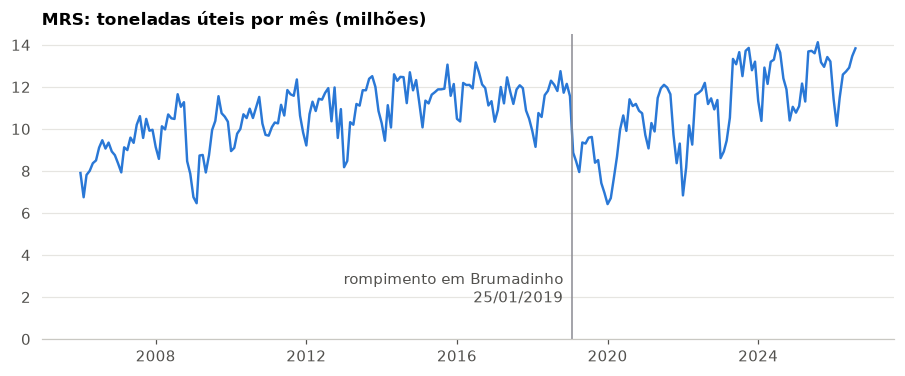

In [2]:
mensal = sql("""
select mes, sum(tu) as tu
from marts.fct_ferrovia_grupo_mensal where ferrovia = 'MRS'
group by 1 order by 1
""")
mensal["mes"] = pd.to_datetime(mensal.mes)
fig, ax = plt.subplots()
ax.plot(mensal.mes, mensal.tu, color=AZUL, linewidth=1.6)
ax.axvline(pd.Timestamp("2019-01-25"), color=CINZA, linewidth=1)
ax.annotate("rompimento em Brumadinho\n25/01/2019", (pd.Timestamp("2019-01-25"), 1.5e6),
            xytext=(-6, 0), textcoords="offset points", ha="right", va="bottom", color="#52514e")
milhoes(ax)
ax.set(title="MRS: toneladas úteis por mês (milhões)", ylim=(0, None))
plt.show()

In [3]:
anual = sql("""
select extract(year from mes)::int as ano, count(distinct mes) as meses, round(sum(tu) / 1e6, 1) as mi_t
from marts.fct_ferrovia_grupo_mensal where ferrovia = 'MRS'
group by 1 order by 1
""")
anual.set_index("ano").T

ano,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
meses,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,...,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,8.0
mi_t,102.0,114.1,119.8,111.0,123.0,130.0,131.4,130.9,138.8,139.7,...,137.1,136.6,106.0,115.2,125.5,126.7,143.7,146.7,153.2,98.6


A MRS sai de 102 mi t em 2006 para 136,6 mi t em 2018. Em 2019 cai para 106 mi t, uma queda de 22%, e só volta a superar 2018 em 2023. Em 2025 bate o recorde da série, com 153,2 mi t. (2026 tem só oito meses.)

## 2. Brumadinho: a queda foi maior que a mina

A barragem de Córrego do Feijão rompeu em 25 de janeiro de 2019. A partir de fevereiro, a estação de mesmo nome não embarca mais nada. Mas a estação explica só uma parte da queda. Comparando fevereiro a dezembro de 2019 com o mesmo período de 2018, por estação de origem do minério:

In [4]:
queda = sql("""
select o.estacao as origem,
       sum(tu) filter (where mes between '2018-02-01' and '2018-12-01') / 1e6 as fev_dez_2018,
       coalesce(sum(tu) filter (where mes between '2019-02-01' and '2019-12-01'), 0) / 1e6 as fev_dez_2019,
       coalesce(sum(tu) filter (where extract(year from mes) = 2025), 0) / 1e6 as ano_2025
from marts.fct_producao_mensal f
join marts.dim_estacoes o on o.estacao_id = f.origem_id
where f.ferrovia = 'MRS' and f.grupo = 'Minério de ferro'
group by 1
""")
queda["diferenca"] = queda.fev_dez_2019 - queda.fev_dez_2018
queda.sort_values("diferenca").head(5).round(1)

,origem,fev_dez_2018,fev_dez_2019,ano_2025,diferenca
15,Otavio Dapieve,35.3,1.8,33.1,-33.5
7,Córrego do Feijão,7.6,0.0,0.0,-7.6
14,Olhos D Água,14.3,9.8,9.3,-4.5
17,Pires,14.1,12.2,21.8,-1.9
24,Viga,2.5,2.1,3.0,-0.3


- **Otávio Dapieve** perdeu 33,5 mi t: foi de 35,3 para 1,8 mi t. É quatro vezes o que saía de Córrego do Feijão (7,6 mi t).
- **Olhos D'Água** perdeu 4,5 mi t, e **Pires**, 1,9 mi t.
- Em 2025, Otávio Dapieve voltou a 33,1 mi t. Córrego do Feijão nunca mais embarcou.

Depois do rompimento, outras minas da região também pararam, o que provavelmente explica a diferença. **Os dados da ANTT não dizem quais minas cada estação atende**, então essa ligação precisa de outra fonte antes de virar conclusão.

## 3. Para onde vai o minério

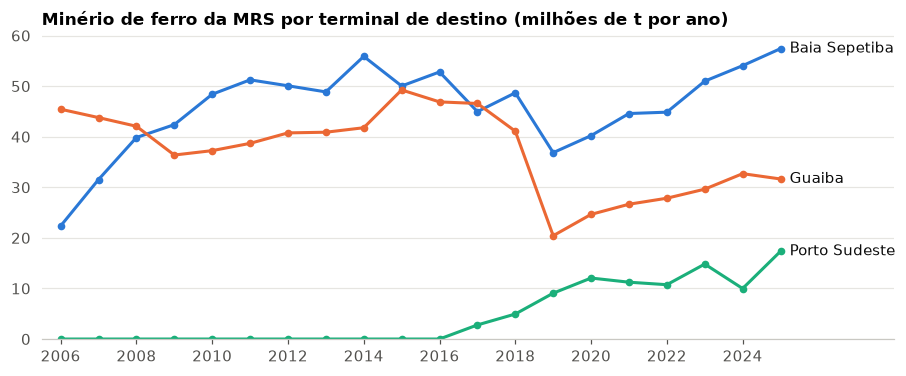

destino,Baia Sepetiba,Guaiba,Porto Sudeste
ano,,,
2006,22.4,45.4,0.0
2018,48.7,41.1,4.9
2019,36.9,20.4,9.1
2025,57.4,31.6,17.3


In [5]:
destinos = sql("""
select extract(year from mes)::int as ano, d.estacao as destino, sum(tu) as tu
from marts.fct_producao_mensal f
join marts.dim_estacoes d on d.estacao_id = f.destino_id
where f.ferrovia = 'MRS' and f.grupo = 'Minério de ferro' and f.mes < '2026-01-01'
group by 1, 2
""").pivot(index="ano", columns="destino", values="tu").fillna(0)
principais = ["Baia Sepetiba", "Guaiba", "Porto Sudeste"]
fig, ax = plt.subplots()
for nome, cor in zip(principais, [AZUL, LARANJA, VERDE]):
    ax.plot(destinos.index, destinos[nome], color=cor, linewidth=2, marker="o", markersize=4)
    ax.annotate(nome, (destinos.index[-1], destinos[nome].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color="#0b0b0b")
ax.set_xlim(2005.5, 2028)
ax.set_xticks(range(2006, 2026, 2))
milhoes(ax)
ax.set(title="Minério de ferro da MRS por terminal de destino (milhões de t por ano)", ylim=(0, None))
plt.show()
(destinos[principais] / 1e6).round(1).loc[[2006, 2018, 2019, 2025]]

Os três terminais na baía de Sepetiba, no RJ, recebem a maior parte do minério, e a divisão entre eles mudou:
- **Guaíba** era o maior destino em 2006, com 45,4 mi t. Caiu para 20,4 mi t em 2019 e em 2025 recebeu 31,6 mi t, ainda abaixo de antes.
- **Baía de Sepetiba** cresceu de 22,4 para 57,4 mi t no mesmo período.
- **Porto Sudeste** aparece em 2017 e recebeu 17,3 mi t em 2025.

O recorde de 2025 não veio de onde a carga ia antes de Brumadinho.

## 4. A dependência do minério não mudou

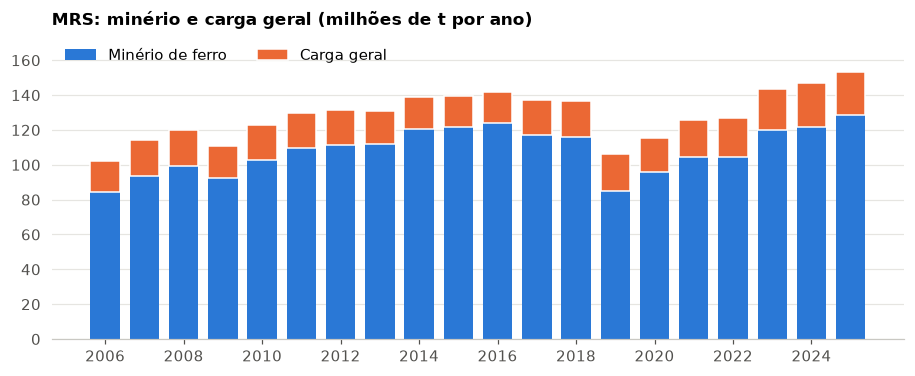

,minerio,carga_geral,pct_minerio
ano,,,
2006,84.1,17.9,82.5
2015,121.4,18.3,86.9
2019,85.2,20.8,80.3
2024,121.5,25.1,82.9
2025,128.8,24.5,84.0


In [6]:
mix = sql("""
select extract(year from mes)::int as ano,
       sum(tu) filter (where grupo = 'Minério de ferro') as minerio,
       sum(tu) filter (where grupo <> 'Minério de ferro') as carga_geral
from marts.fct_ferrovia_grupo_mensal where ferrovia = 'MRS' and mes < '2026-01-01'
group by 1 order by 1
""").set_index("ano")
fig, ax = plt.subplots()
ax.bar(mix.index, mix.minerio, color=AZUL, width=0.75, label="Minério de ferro")
ax.bar(mix.index, mix.carga_geral, bottom=mix.minerio, color=LARANJA, width=0.75, label="Carga geral",
       edgecolor="white", linewidth=1)
milhoes(ax)
ax.legend(loc="upper left", ncols=2)
ax.set_xticks(range(2006, 2026, 2))
ax.set(title="MRS: minério e carga geral (milhões de t por ano)", ylim=(0, 175e6))
plt.show()
(mix.assign(pct_minerio=100 * mix.minerio / (mix.minerio + mix.carga_geral)) / [1e6, 1e6, 1]).round(1).loc[[2006, 2015, 2019, 2024, 2025]]

A carga geral cresceu de 17,9 mi t em 2006 para 25,1 mi t em 2024, ou 40%. Como o minério cresceu quase na mesma proporção, a participação dele ficou entre 80% e 87% durante os 20 anos, com 84% em 2025. **A empresa transporta mais carga geral, mas não ficou menos dependente do minério.**

### O que cresceu na carga geral

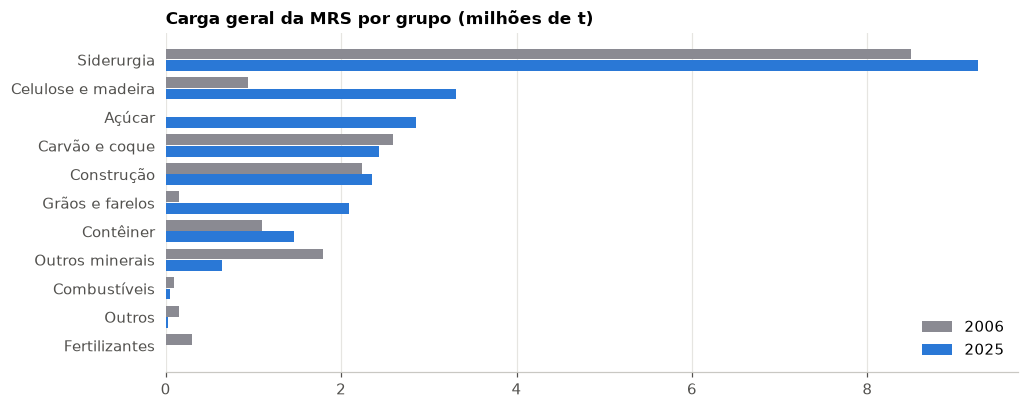

,grupo,a2006,a2025
10,Siderurgia,8.50,9.26
9,Celulose e madeira,0.93,3.31
8,Açúcar,0.00,2.85
7,Carvão e coque,2.59,2.43
6,Construção,2.24,2.35
5,Grãos e farelos,0.15,2.09
4,Contêiner,1.10,1.46
3,Outros minerais,1.80,0.64
2,Combustíveis,0.10,0.05
1,Outros,0.15,0.02


In [7]:
geral = sql("""
select grupo,
       coalesce(sum(tu) filter (where extract(year from mes) = 2006), 0) / 1e6 as a2006,
       coalesce(sum(tu) filter (where extract(year from mes) = 2025), 0) / 1e6 as a2025
from marts.fct_ferrovia_grupo_mensal
where ferrovia = 'MRS' and grupo <> 'Minério de ferro'
group by 1 order by a2025
""")
fig, ax = plt.subplots(figsize=(10, 4))
y = range(len(geral))
ax.barh([i + 0.2 for i in y], geral.a2006, height=0.38, color=CINZA, label="2006")
ax.barh([i - 0.2 for i in y], geral.a2025, height=0.38, color=AZUL, label="2025")
ax.set_yticks(list(y), geral.grupo)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set(title="Carga geral da MRS por grupo (milhões de t)")
plt.show()
geral.sort_values("a2025", ascending=False).round(2)

- **Siderurgia** continua sendo a maior carga geral: 9,3 mi t em 2025, contra 8,5 em 2006.
- **Celulose e madeira** foi de 0,9 para 3,3 mi t, 3,5 vezes mais.
- **Grãos e farelos** foram de 0,15 para 2,1 mi t.
- **Açúcar** começa em 2007 e somou 2,9 mi t em 2025.

## 5. Fluxos de fora da malha da MRS

O dicionário de dados da ANTT define `ferrovia` como a **concessionária responsável pelo fluxo**. Por isso aparecem na conta da MRS estações do interior paulista que estão em trilhos de outra concessionária:

In [8]:
sql("""
select o.estacao as origem, d.estacao as destino, string_agg(distinct f.grupo, ', ') as carga,
       round(sum(f.tu) / 1e6, 2) as mi_t_2025, round(sum(f.tku)::numeric / sum(f.tu)) as km
from marts.fct_producao_mensal f
join marts.dim_estacoes o on o.estacao_id = f.origem_id
join marts.dim_estacoes d on d.estacao_id = f.destino_id
where f.ferrovia = 'MRS' and extract(year from f.mes) = 2025
  and o.estacao in ('Pederneiras', 'Pradopolis', 'Itirapina', 'Rio Preto Paulista', 'Votuporanga')
group by 1, 2 order by 4 desc limit 8
""")

,origem,destino,carga,mi_t_2025,km
0,Pederneiras,Santos,"Celulose e madeira, Grãos e farelos",3.89,521.0
1,Pradopolis,Santos,Açúcar,0.89,539.0
2,Pederneiras,Conceiçãozinha,"Açúcar, Grãos e farelos",0.78,526.0
3,Itirapina,Santos,Açúcar,0.74,393.0
4,Rio Preto Paulista,Santos,Açúcar,0.34,671.0
5,Votuporanga,Santos,Açúcar,0.32,767.0
6,Pradopolis,Conceiçãozinha,Açúcar,0.22,546.0
7,Pederneiras,Estação TUF,"Açúcar, Grãos e farelos",0.16,509.0


O maior desses fluxos é Pederneiras → Santos, com 3,9 mi t em 2025. Somar a produção por "ferrovia" mede carga sob responsabilidade da concessionária, não carga que rodou na malha dela. Uma comparação de uso de malha precisaria de outra fonte.

## 6. A safra aparece nos trilhos

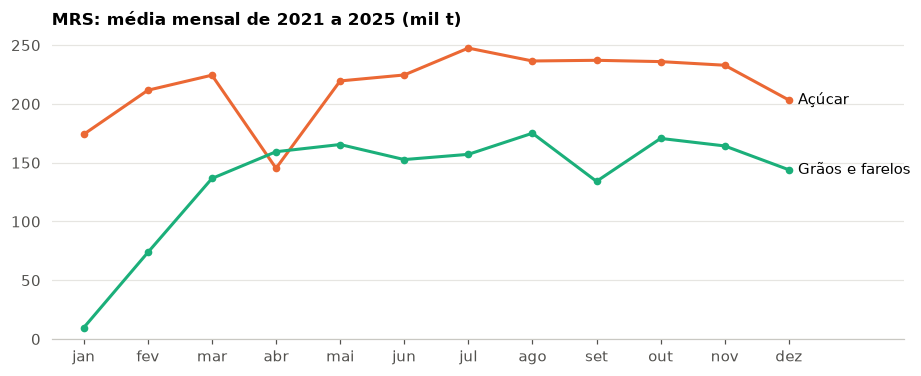

mes,1,2,3,4,5,6,7,8,9,10,11,12
grupo,,,,,,,,,,,,
Açúcar,174.0,212.0,224.0,145.0,220.0,225.0,247.0,237.0,237.0,236.0,233.0,203.0
Grãos e farelos,10.0,74.0,137.0,159.0,165.0,153.0,157.0,175.0,134.0,171.0,164.0,144.0


In [9]:
safra = sql("""
select extract(month from mes)::int as mes, grupo, avg(tu) as tu
from marts.fct_ferrovia_grupo_mensal
where ferrovia = 'MRS' and grupo in ('Açúcar', 'Grãos e farelos') and mes between '2021-01-01' and '2025-12-01'
group by 1, 2
""").pivot(index="mes", columns="grupo", values="tu")
fig, ax = plt.subplots()
for nome, cor in [("Açúcar", LARANJA), ("Grãos e farelos", VERDE)]:
    ax.plot(safra.index, safra[nome] / 1e3, color=cor, linewidth=2, marker="o", markersize=4)
    ax.annotate(nome, (12, safra[nome].iloc[-1] / 1e3), xytext=(6, 0), textcoords="offset points", va="center")
ax.set_xticks(range(1, 13), ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"])
ax.set_xlim(0.5, 13.8)
ax.set(title="MRS: média mensal de 2021 a 2025 (mil t)", ylim=(0, None))
plt.show()
(safra / 1e3).round(0).T

Os grãos quase somem em janeiro, com média de 10 mil t, e chegam a 137 mil t em março, quando a soja começa a ser colhida. O açúcar oscila menos, entre 145 e 247 mil t por mês. Os dois picos estão no segundo semestre.

## 7. A MRS entre as ferrovias, em 2025

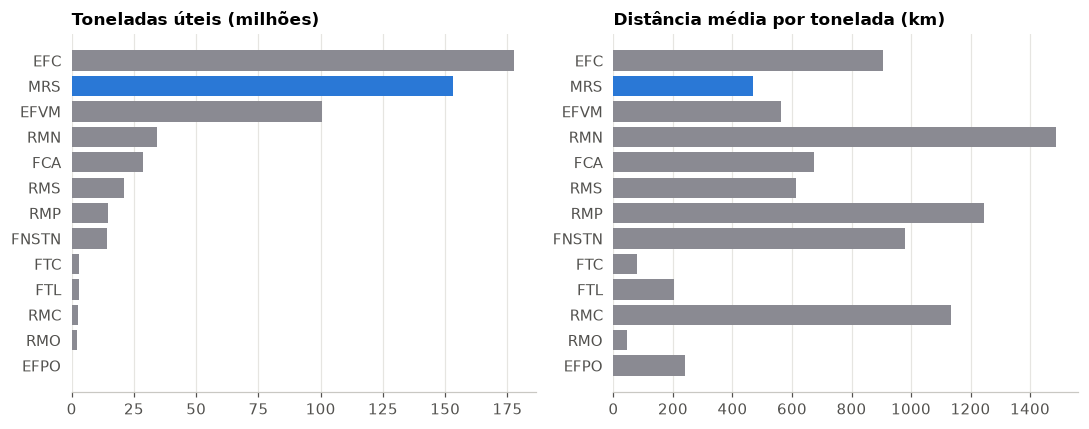

,ferrovia,mi_t,km
0,EFC,177.7,907.0
1,MRS,153.2,467.9
2,EFVM,100.7,562.3
3,RMN,34.1,1486.8
4,FCA,28.7,673.7
5,RMS,21.0,612.6
6,RMP,14.5,1246.9
7,FNSTN,14.0,979.9
8,FTC,3.1,77.8
9,FTL,2.8,203.0


In [10]:
ferrovias = sql("""
select ferrovia, sum(tu) as tu, sum(tku)::numeric / sum(tu) as km
from marts.fct_ferrovia_grupo_mensal where extract(year from mes) = 2025
group by 1 order by tu desc
""")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
cores = [AZUL if f == "MRS" else CINZA for f in ferrovias.ferrovia]
a1.barh(ferrovias.ferrovia, ferrovias.tu, color=cores); a1.invert_yaxis()
a1.xaxis.set_major_formatter(lambda v, _: f"{v / 1e6:.0f}")
a1.set(title="Toneladas úteis (milhões)")
a2.barh(ferrovias.ferrovia, ferrovias.km, color=cores); a2.invert_yaxis()
a2.set(title="Distância média por tonelada (km)")
for a in (a1, a2):
    a.grid(axis="x"); a.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
ferrovias.assign(mi_t=ferrovias.tu / 1e6).round(1)[["ferrovia", "mi_t", "km"]]

- **Tonelagem:** a MRS é a segunda ferrovia do país, com 153,2 mi t, atrás da Estrada de Ferro Carajás, com 177,7 mi t.
- **Distância:** cada tonelada da MRS viaja em média 468 km, metade dos 907 km da Carajás e menos ainda que os 1.487 km da Rumo Malha Norte, que leva grãos de Mato Grosso a São Paulo.

É uma ferrovia de muito volume em distância curta: liga as minas do Quadrilátero Ferrífero aos portos do Rio e de Santos, e as siderúrgicas do Vale do Paraíba.